In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import json

df = pd.read_csv('USvideos.csv', encoding='utf-8')
with open('US_category_id.json', 'r', encoding='utf-8') as f:
 cat_data = json.load(f)
cat_dict = {int(item['id']): item['snippet']['title'] for item in cat_data['items']}
df['category_name'] = df['category_id'].map(cat_dict)

In [2]:
df['trending_date'] = pd.to_datetime(
    df['trending_date'], format='%y.%d.%m', errors='coerce'
).dt.tz_localize(None)
df['publish_time'] = pd.to_datetime(df['publish_time'], errors='coerce').dt.tz_localize(None)

df['engagement_rate'] = (
    (df['likes'] + df['dislikes'] + df['comment_count']) / df['views']
) * 100
df['like_rate'] = (df['likes'] / df['views']) * 100
df['dislike_rate'] = (df['dislikes'] / df['views']) * 100
df['days_to_trend'] = (
    df['trending_date'] - df['publish_time'].dt.normalize()
).dt.days

df_unique = df.drop_duplicates(subset=['video_id'], keep='first').copy()

print(
    len(df_unique),
)

6351


In [8]:
numeric_cols = [
    'views',
    'likes',
    'dislikes',
    'comment_count',
    'engagement_rate',
    'like_rate',
]

corr_matrix = df_unique[numeric_cols].corr()
display(corr_matrix)

category_stats = (
    df_unique.groupby('category_name')[
        ['views', 'likes', 'engagement_rate', 'days_to_trend']
    ]
    .mean()
    .sort_values(by='views', ascending=False)
)

print('\n Category Stats')
display(category_stats)

,views,likes,dislikes,comment_count,engagement_rate,like_rate
views,1.000000,0.761127,0.396135,0.599628,0.057128,0.058687
likes,0.761127,1.000000,0.360274,0.806198,0.318552,0.318251
dislikes,0.396135,0.360274,1.000000,0.679838,0.097088,0.031497
comment_count,0.599628,0.806198,0.679838,1.000000,0.258414,0.206036
engagement_rate,0.057128,0.318552,0.097088,0.258414,1.000000,0.974911
like_rate,0.058687,0.318251,0.031497,0.206036,0.974911,1.000000



 Category Stats


,views,likes,engagement_rate,days_to_trend
category_name,,,,
Music,1.387621e+06,103435.185232,8.234088,22.692115
Gaming,1.211844e+06,49763.135922,5.482981,41.330097
Nonprofits & Activism,1.025217e+06,111002.785714,4.830642,3.500000
Film & Animation,9.204330e+05,30769.534591,4.029484,72.094340
Sports,8.302815e+05,19882.175166,2.039082,20.008869
Entertainment,8.171231e+05,27329.894997,3.843338,18.155034
Comedy,7.729546e+05,39168.983547,5.689227,10.756856
People & Blogs,7.127675e+05,32216.226908,5.505346,20.116466
Science & Technology,5.843225e+05,18068.189474,4.231290,29.126316


=== TOP 10 CATEGORIES BY AVERAGE VIEWS ===
category_name
Music                    1.387621e+06
Gaming                   1.211844e+06
Nonprofits & Activism    1.025217e+06
Film & Animation         9.204330e+05
Sports                   8.302815e+05
Entertainment            8.171231e+05
Comedy                   7.729546e+05
People & Blogs           7.127675e+05
Science & Technology     5.843225e+05
Howto & Style            4.731389e+05
Name: views, dtype: float64


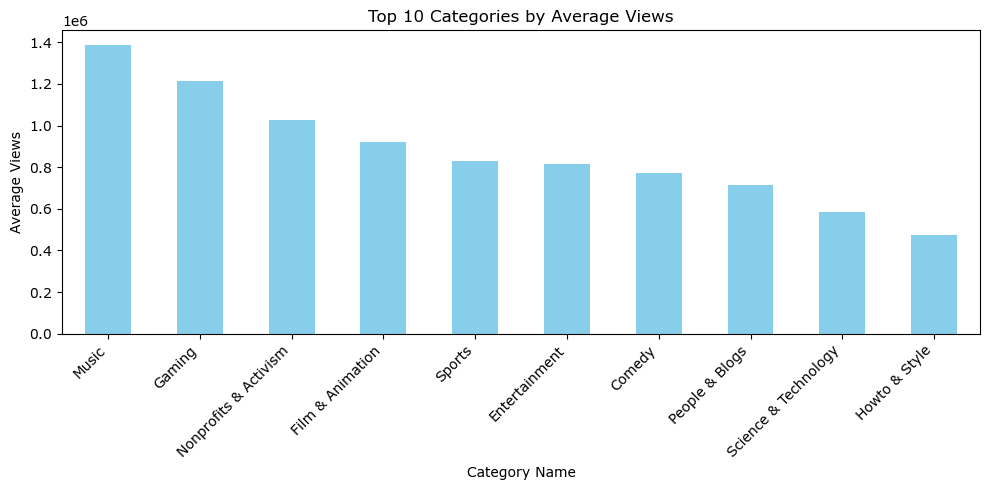

In [4]:
# Top 10 Categories by AVG of Total Revenue

avg_views_by_cat = df_unique.groupby('category_name')['views'].mean()

top_10_categories = avg_views_by_cat.nlargest(10)

print("=== TOP 10 CATEGORIES BY AVERAGE VIEWS ===")
print(top_10_categories)

plt.figure(figsize=(10, 5))
top_10_categories.plot(kind='bar', color='skyblue')

plt.title('Top 10 Categories by Average Views')
plt.xlabel('Category Name')
plt.ylabel('Average Views')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

publish_day
Monday        985
Tuesday      1061
Wednesday    1097
Thursday     1055
Friday       1047
Saturday      547
Sunday        559
Name: count, dtype: int64


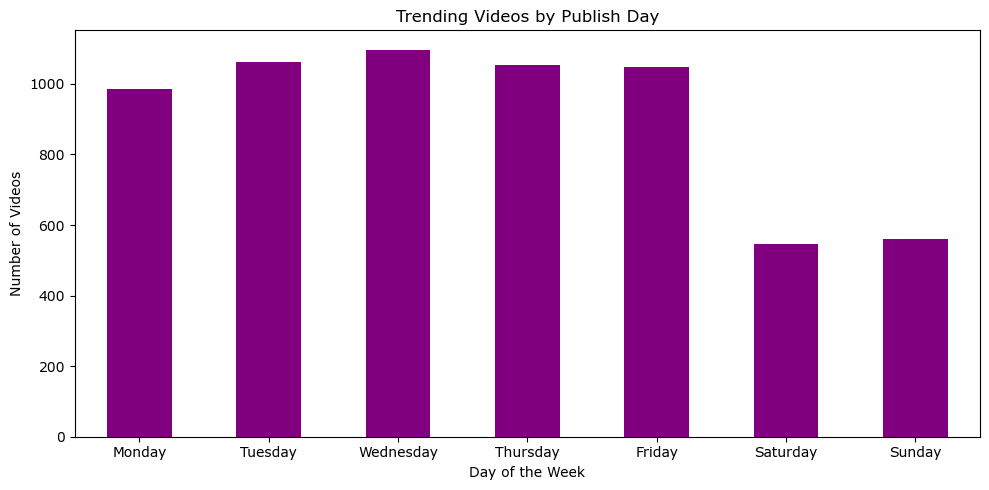

In [5]:
# Trending videos bu publish days
df_unique['publish_day'] = df_unique['publish_time'].dt.day_name()

days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
publish_by_day = df_unique['publish_day'].value_counts().reindex(days_order)

print(publish_by_day)

plt.figure(figsize=(10, 5))
publish_by_day.plot(kind='bar', color='purple')
plt.title('Trending Videos by Publish Day')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Videos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

count    6351.000000
mean       49.774524
std        19.711426
min         3.000000
25%        35.000000
50%        48.000000
75%        62.000000
max       100.000000
Name: title_length, dtype: float64


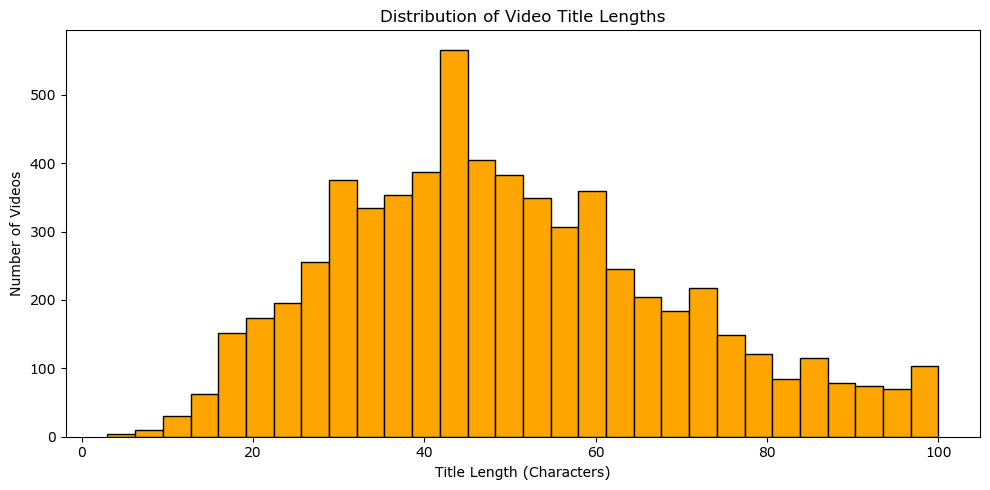

In [5]:
# Video Title Length Analysis

df_unique['title_length'] = df_unique['title'].str.len()

print(df_unique['title_length'].describe())

plt.figure(figsize=(10, 5))
df_unique['title_length'].plot(
    kind='hist', bins=30, color='orange', edgecolor='black'
)
plt.title('Distribution of Video Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Number of Videos')
plt.tight_layout()
plt.show()

count    6351.000000
mean       19.811211
std        12.240803
min         0.000000
25%        10.000000
50%        19.000000
75%        29.000000
max        69.000000
Name: tag_count, dtype: float64


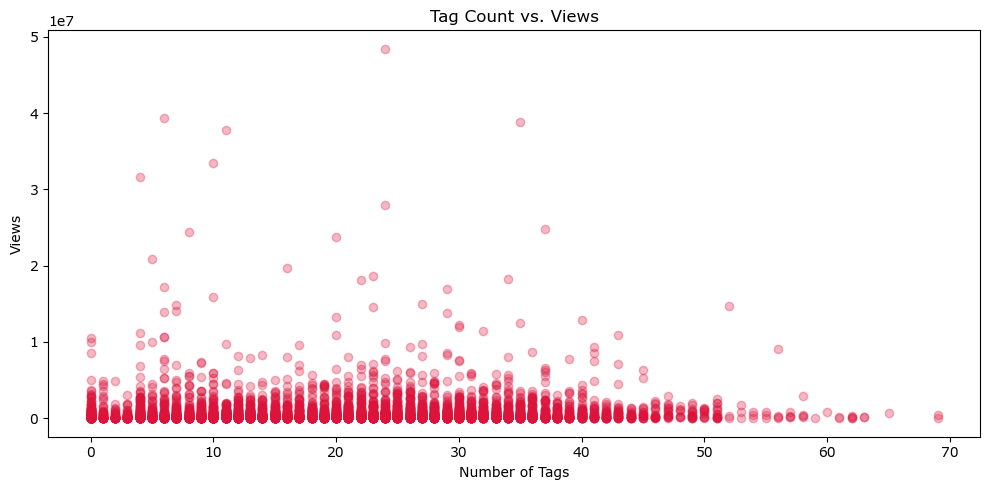

In [6]:
# Tag Count vs Views Analysis

def get_tag_count(x):
  if x == '[none]' or pd.isna(x):
    return 0
  return len(str(x).split('|'))


df_unique['tag_count'] = df_unique['tags'].apply(get_tag_count)

print(df_unique['tag_count'].describe())

plt.figure(figsize=(10, 5))
plt.scatter(
    df_unique['tag_count'], df_unique['views'], alpha=0.3, color='crimson'
)
plt.title('Tag Count vs. Views')
plt.xlabel('Number of Tags')
plt.ylabel('Views')
plt.tight_layout()
plt.show()

count    6351.000000
mean      996.424028
std       841.075514
min         0.000000
25%       388.000000
50%       804.000000
75%      1348.000000
max      5123.000000
Name: description_length, dtype: float64


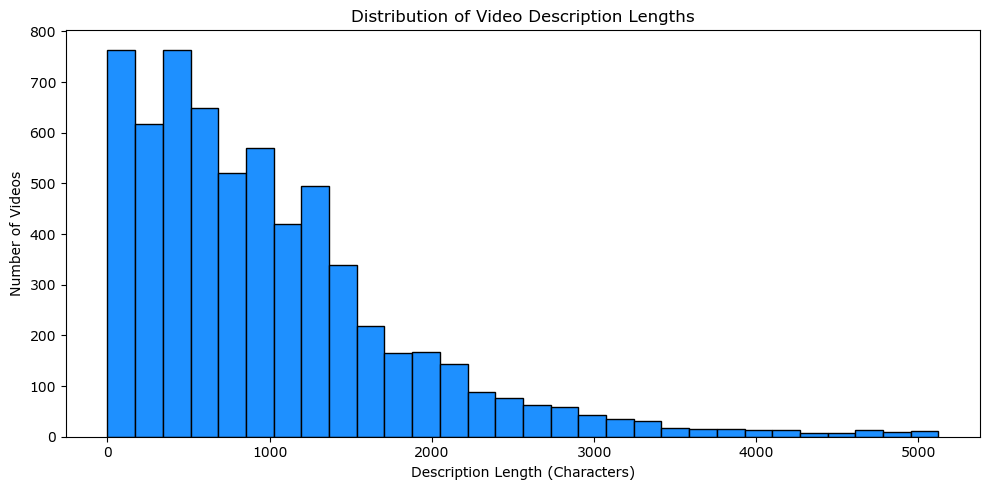

In [5]:
# Description Length Analysis

df_unique['description_length'] = df_unique['description'].fillna('').str.len()

print(df_unique['description_length'].describe())

plt.figure(figsize=(10, 5))
df_unique['description_length'].plot(
    kind='hist', bins=30, color='dodgerblue', edgecolor='black'
)
plt.title('Distribution of Video Description Lengths')
plt.xlabel('Description Length (Characters)')
plt.ylabel('Number of Videos')
plt.tight_layout()
plt.show()

category_id
24    1619
10     799
26     595
23     547
25     505
22     498
17     451
28     380
1      318
27     250
15     138
20     103
2       70
19      60
29      14
43       4
Name: count, dtype: int64


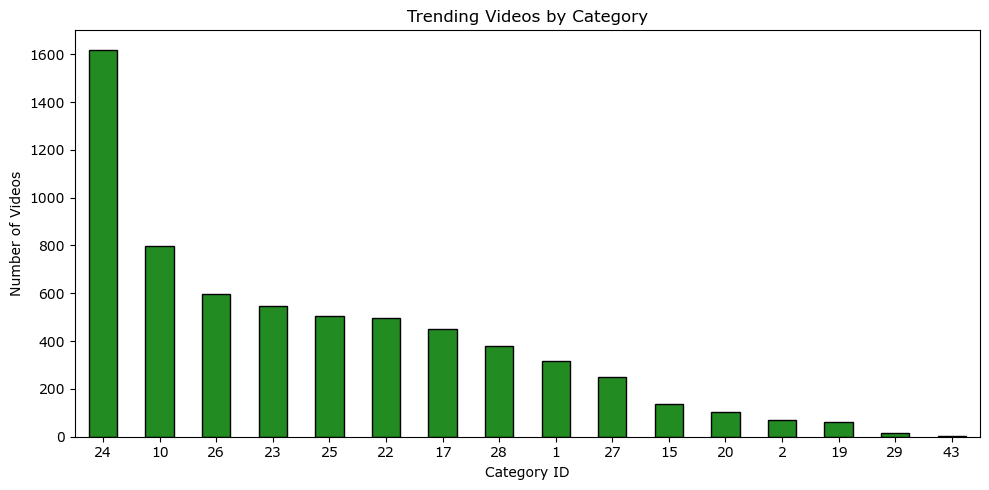

In [6]:
# Top Trending Video Categories

top_categories = df_unique['category_id'].value_counts()

print(top_categories)

plt.figure(figsize=(10, 5))
top_categories.plot(kind='bar', color='forestgreen', edgecolor='black')
plt.title('Trending Videos by Category')
plt.xlabel('Category ID')
plt.ylabel('Number of Videos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

/private/var/mobile/Containers/Data/Application/9A0583A3-1364-4862-84E6-A4CBD1CB4DF1/tmp/ipykernel_10040/2076071710.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


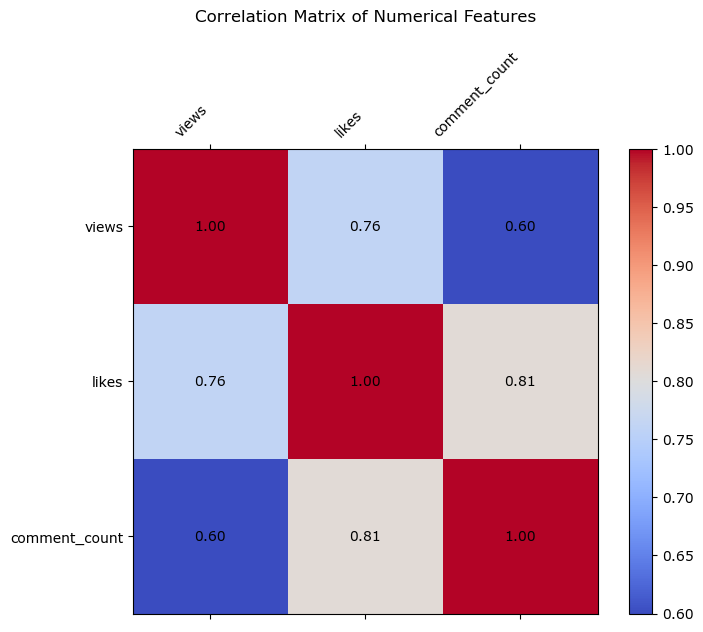

In [3]:
# Correlation Matrix Heatmap

num_cols = [
    'views',
    'likes',
    'comment_count',
    'title_length',
    'description_length',
    'tag_count',
]
existing_cols = [c for c in num_cols if c in df_unique.columns]

corr = df_unique[existing_cols].corr()

plt.figure(figsize=(8, 6))
cax = plt.matshow(corr, cmap='coolwarm', fignum=1)
plt.colorbar(cax)

plt.xticks(
    range(len(existing_cols)), existing_cols, rotation=45, ha='right'
)
plt.yticks(range(len(existing_cols)), existing_cols)

for i in range(len(existing_cols)):
  for j in range(len(existing_cols)):
    plt.text(
        j,
        i,
        f'{corr.iloc[i, j]:.2f}',
        ha='center',
        va='center',
        color='black',
    )

plt.title('Correlation Matrix of Numerical Features', pad=20)
plt.tight_layout()
plt.show()

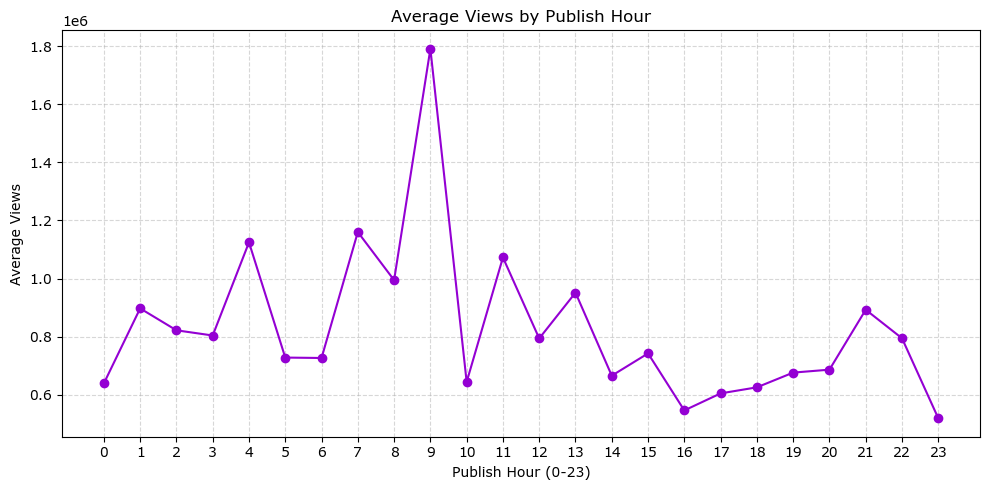

In [4]:
# Publish Hour vs Average Views Analysis

df_unique['publish_hour'] = df_unique['publish_time'].dt.hour
hourly_views = df_unique.groupby('publish_hour')['views'].mean()

plt.figure(figsize=(10, 5))
plt.plot(
    hourly_views.index,
    hourly_views.values,
    marker='o',
    linestyle='-',
    color='darkviolet',
)
plt.title('Average Views by Publish Hour')
plt.xlabel('Publish Hour (0-23)')
plt.ylabel('Average Views')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

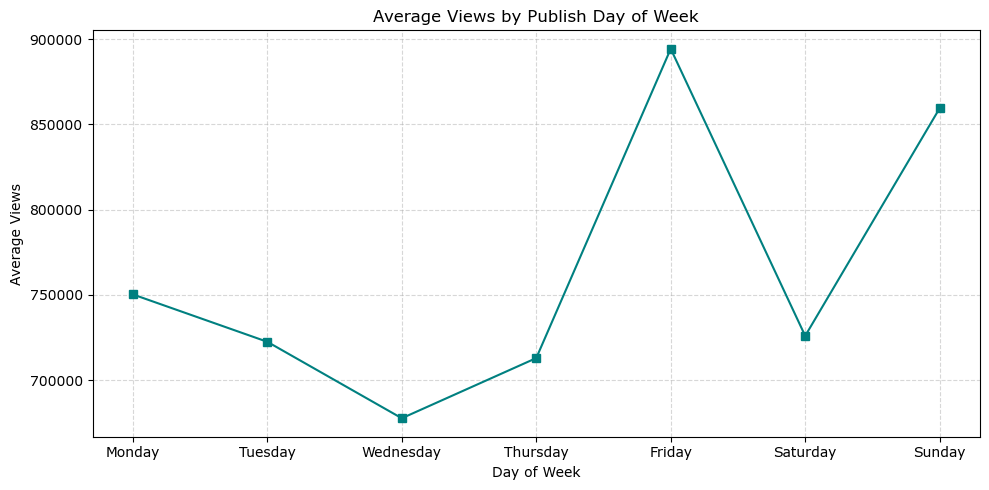

In [3]:
# Publish Day of Week vs. Average Views Analysis

df_unique['publish_day'] = df_unique['publish_time'].dt.day_name()

days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
daily_views = (
    df_unique.groupby('publish_day')['views'].mean().reindex(days_order)
)

plt.figure(figsize=(10, 5))
plt.plot(
    daily_views.index,
    daily_views.values,
    marker='s',
    linestyle='-',
    color='teal',
)
plt.title('Average Views by Publish Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Views')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

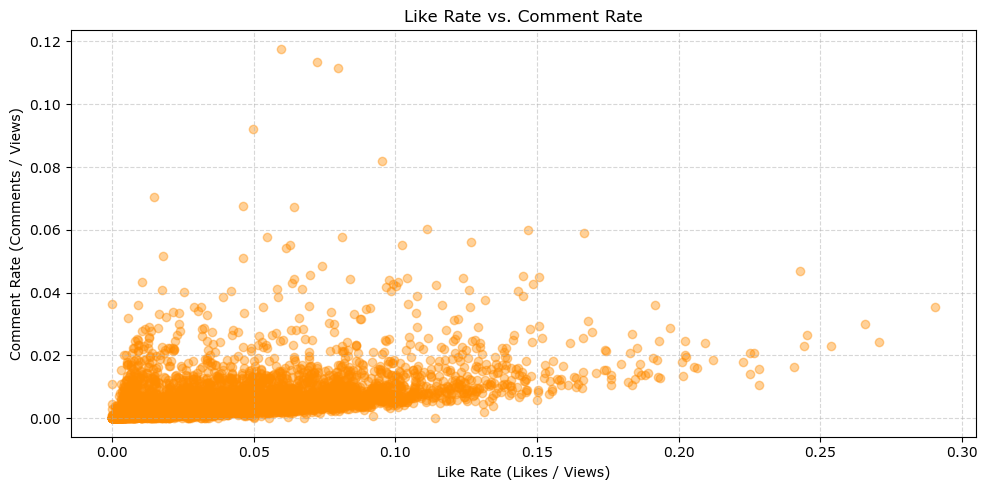

In [4]:
#  Sentiment Analysis vs. Engagement Rate (Likes to Views Ratio)

df_unique['like_rate'] = df_unique['likes'] / df_unique['views']

def get_comment_ratio(row):
    if row['views'] == 0:
        return 0
    return row['comment_count'] / row['views']

df_unique['comment_rate'] = df_unique.apply(get_comment_ratio, axis=1)

plt.figure(figsize=(10, 5))
plt.scatter(df_unique['like_rate'], df_unique['comment_rate'], alpha=0.4, color='darkorange')
plt.title('Like Rate vs. Comment Rate')
plt.xlabel('Like Rate (Likes / Views)')
plt.ylabel('Comment Rate (Comments / Views)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

count    6351.000000
mean       22.520548
std       209.963344
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max      4215.000000
Name: days_to_trend, dtype: float64


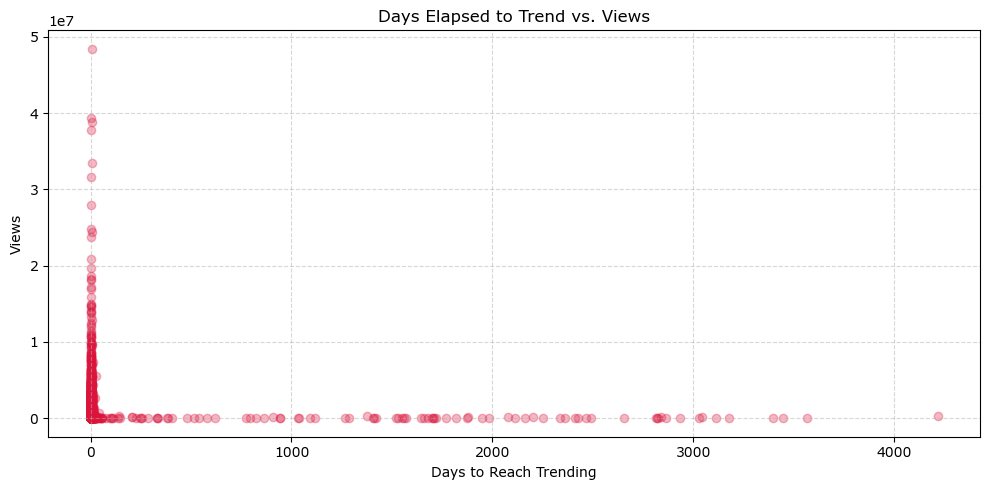

In [6]:
# Days Elapsed to Trend vs. Views Analysis

def calculate_days_to_trend(row):
  publish_date = row['publish_time'].date()
  trending_date = row['trending_date'].date()
  return (trending_date - publish_date).days


df_unique['days_to_trend'] = df_unique.apply(calculate_days_to_trend, axis=1)

print(df_unique['days_to_trend'].describe())

plt.figure(figsize=(10, 5))
plt.scatter(
    df_unique['days_to_trend'], df_unique['views'], alpha=0.3, color='crimson'
)
plt.title('Days Elapsed to Trend vs. Views')
plt.xlabel('Days to Reach Trending')
plt.ylabel('Views')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

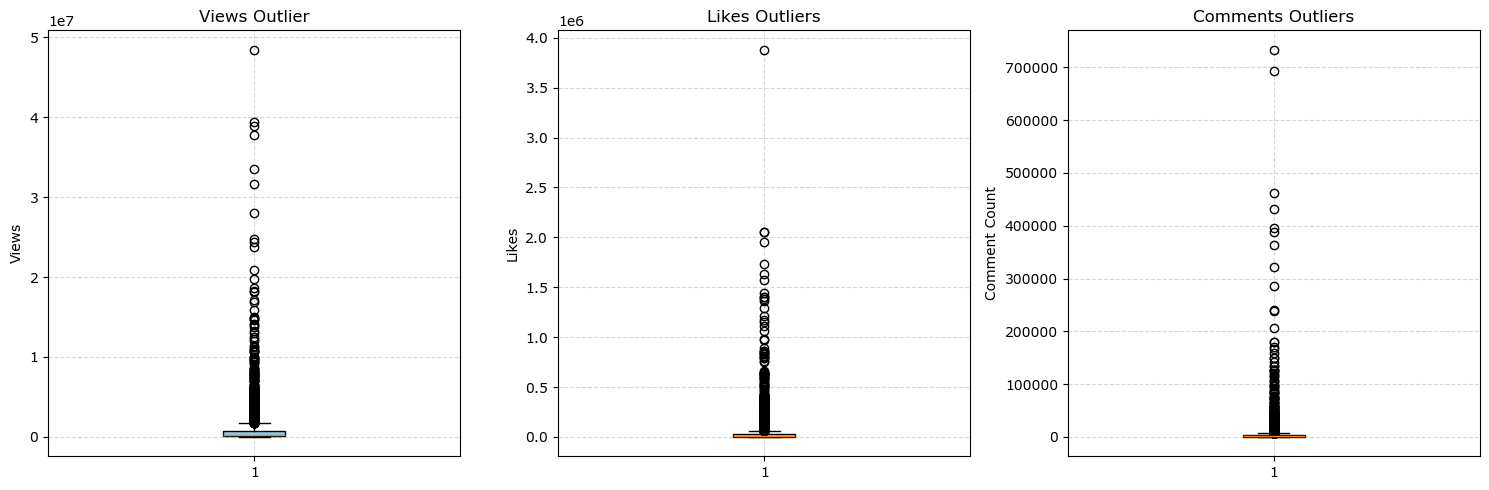

In [9]:
# Outliers Analysis for Views, Likes, and Comments

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

ax1.boxplot(df_unique['views'], vert=True, patch_artist=True, boxprops=dict(facecolor='skyblue'))
ax1.set_title('Views Outlier')
ax1.set_ylabel('Views')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.boxplot(df_unique['likes'], vert=True, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
ax2.set_title('Likes Outliers')
ax2.set_ylabel('Likes')
ax2.grid(True, linestyle='--', alpha=0.5)

ax3.boxplot(df_unique['comment_count'], vert=True, patch_artist=True, boxprops=dict(facecolor='salmon'))
ax3.set_title('Comments Outliers')
ax3.set_ylabel('Comment Count')
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
# Final Summary Table of Key Metrics

summary_cols = [
    'views',
    'likes',
    'comment_count',
    'title_length',
    'description_length',
    'tag_count',
]
existing_summary_cols = [c for c in summary_cols if c in df_unique.columns]

summary_stats = df_unique[existing_summary_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary_stats.rename(columns={'50%': 'median'}, inplace=True)
print("Summary")
print(summary_stats.to_string())

Summary
                count           mean           std    min    median         max
views          6351.0  758209.564478  1.928993e+06  549.0  270902.0  48431654.0
likes          6351.0   34493.569832  1.162439e+05    0.0    7987.0   3880071.0
comment_count  6351.0    4501.707290  2.146022e+04    0.0     921.0    733373.0
